# Monsoon Rainfall Analysis and Prediction for Indian Subdivisions

**Project type:** Final Year Machine Learning Project
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn
**Dataset:** Monsoon rainfall (June to September) of 36 meteorological subdivisions of India, 1901-2021

---

## 1. Introduction

Rainfall during the monsoon season (June to September) decides crop yield, water supply and flood risk for a large part of India. Knowing in advance how much rain a region will receive helps farmers, planners and local authorities to prepare.

In this project we study the rainfall data of 36 subdivisions over 121 years and build two kinds of machine learning models:

1. **Classification:** predict whether the monsoon rainfall of a subdivision in a year is **Low, Medium or High**.
2. **Regression:** predict the **total monsoon rainfall (mm)**.

## 2. Objectives

- Understand and clean the dataset.
- Explore rainfall patterns by year, month and subdivision.
- Train and compare Logistic Regression, Decision Tree and Random Forest for classification.
- Train and compare Linear Regression, Decision Tree and Random Forest for regression.
- Select and save the best model for each task.

## Contents

1. Data Understanding
2. Data Cleaning
3. Exploratory Data Analysis
4. Problem Setup and Train-Test Split
5. Classification Models
6. Regression Models
7. Model Comparison
8. Saving the Models
9. Conclusion and Future Scope

In [2]:
# Core libraries
import os
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Scikit-learn tools
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)

RANDOM_STATE = 42          # fixed seed so results can be repeated
os.makedirs('images', exist_ok=True)
os.makedirs('models', exist_ok=True)
print('Libraries loaded successfully')

Libraries loaded successfully


---
## 3. Data Understanding

We begin by loading the file and looking at its size, column types, missing values and duplicates.

In [2]:
# Load the dataset
df = pd.read_csv('data/rainfaLLIndia.csv')

print('Shape of dataset (rows, columns):', df.shape)
df.head()

Shape of dataset (rows, columns): (4332, 7)


,subdivision,YEAR,JUN,JUL,AUG,SEP,JUN-SEP
0,ANDAMAN & NICOBAR ISLAND,1901,517.5,365.1,481.1,332.6,1696.3
1,ANDAMAN & NICOBAR ISLAND,1902,537.1,228.9,753.7,666.2,2185.9
2,ANDAMAN & NICOBAR ISLAND,1903,479.9,728.4,326.7,339.0,1874.0
3,ANDAMAN & NICOBAR ISLAND,1904,495.1,502.0,160.1,820.4,1977.6
4,ANDAMAN & NICOBAR ISLAND,1905,628.7,368.7,330.5,297.0,1624.9


In [3]:
# Column names, data types and basic information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4332 entries, 0 to 4331
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   subdivision  4332 non-null   str    
 1   YEAR         4332 non-null   int64  
 2   JUN          4332 non-null   float64
 3   JUL          4332 non-null   float64
 4   AUG          4332 non-null   float64
 5   SEP          4332 non-null   float64
 6   JUN-SEP      4332 non-null   float64
dtypes: float64(5), int64(1), str(1)
memory usage: 237.0 KB


In [4]:
# Statistical summary of the numeric columns
df.describe().round(2)

,YEAR,JUN,JUL,AUG,SEP,JUN-SEP
count,4332.00,4332.00,4332.00,4332.00,4332.00,4332.00
mean,1961.22,227.58,344.36,288.91,197.40,1057.11
std,34.87,232.09,268.23,189.93,136.68,706.56
min,1901.00,-99.90,-99.90,-99.90,-99.90,-99.90
25%,1931.00,70.40,173.88,155.00,99.88,565.92
50%,1961.00,137.65,283.25,258.00,172.90,877.30
75%,1991.00,303.73,416.18,377.62,266.50,1287.90
max,2021.00,1609.90,2362.80,1664.60,1222.00,4536.90


In [5]:
# Missing values and duplicate rows
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('Number of subdivisions:', df['subdivision'].nunique())
print('Years covered:', df['YEAR'].min(), 'to', df['YEAR'].max())

Missing values per column:
subdivision    0
YEAR           0
JUN            0
JUL            0
AUG            0
SEP            0
JUN-SEP        0
dtype: int64

Duplicate rows: 0
Number of subdivisions: 36
Years covered: 1901 to 2021


**Observations**

- The dataset has **4,332 rows and 7 columns**: the subdivision name, the year, rainfall for June, July, August and September, and the seasonal total (`JUN-SEP`). All rainfall values are in millimetres (mm).
- It covers **36 subdivisions** from **1901 to 2021**. Data types are correct: one text column, one integer column (`YEAR`) and five decimal columns.
- `isnull()` reports **no missing values** and there are **no duplicate rows**.
- However, the `min` row of the summary table shows **-99.9** in every rainfall column. Rainfall cannot be negative, so something is wrong. We investigate this in the next step.

---
## 4. Data Cleaning

In [6]:
# pandas shows no missing values, but describe() shows a minimum of -99.9.
# Rainfall can never be negative, so let us check these values.
rain_cols = ['JUN', 'JUL', 'AUG', 'SEP', 'JUN-SEP']
print('Count of -99.9 values in each column:')
print((df[rain_cols] == -99.9).sum())

print('\nRows containing -99.9:')
df[(df[rain_cols] == -99.9).any(axis=1)]

Count of -99.9 values in each column:
JUN         5
JUL         7
AUG         4
SEP         6
JUN-SEP    10
dtype: int64

Rows containing -99.9:


,subdivision,YEAR,JUN,JUL,AUG,SEP,JUN-SEP
30,ANDAMAN & NICOBAR ISLAND,1932,-99.9,-99.9,-99.9,-99.9,-99.9
40,ANDAMAN & NICOBAR ISLAND,1942,-99.9,-99.9,-99.9,-99.9,-99.9
42,ANDAMAN & NICOBAR ISLAND,1947,965.6,490.0,293.7,-99.9,-99.9
116,ARUNACHAL PRADESH,1916,1124.9,-99.9,629.7,333.9,-99.9
150,ARUNACHAL PRADESH,1950,-99.9,377.6,241.8,285.8,-99.9
1900,JAMMU & KASHMIR,2009,60.1,-99.9,100.4,50.1,-99.9
4228,LAKSHDWEEP,1917,-99.9,-99.9,-99.9,-99.9,-99.9
4231,LAKSHDWEEP,1921,326.2,163.7,235.5,-99.9,-99.9
4237,LAKSHDWEEP,1927,181.2,-99.9,42.0,256.0,-99.9
4256,LAKSHDWEEP,1946,-99.9,-99.9,-99.9,-99.9,-99.9


**Observation:** The value `-99.9` is a placeholder that means "data not available". Because it is a number, pandas did not count it as missing. In total **10 rows** are affected (Andaman & Nicobar: 3, Arunachal Pradesh: 2, Jammu & Kashmir: 1, Lakshadweep: 4). In every one of these rows the seasonal total `JUN-SEP` is missing. If we left these values as they are, they would pull averages down and confuse the models.

In [7]:
# Treat -99.9 as a missing value (NaN)
df_clean = df.copy()
df_clean[rain_cols] = df_clean[rain_cols].replace(-99.9, np.nan)

print('Missing values after replacing -99.9:')
print(df_clean.isnull().sum())

# The target column (JUN-SEP) is missing in all of these rows, so they
# cannot be used for training. Only a small share of the data is affected.
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=['JUN-SEP']).reset_index(drop=True)
print(f'\nRows removed: {rows_before - len(df_clean)} ({(rows_before - len(df_clean)) / rows_before * 100:.2f}% of the data)')
print('Remaining missing values:', df_clean.isnull().sum().sum())

Missing values after replacing -99.9:
subdivision     0
YEAR            0
JUN             5
JUL             7
AUG             4
SEP             6
JUN-SEP        10
dtype: int64

Rows removed: 10 (0.23% of the data)
Remaining missing values: 0


In [8]:
# Remove duplicate rows (if any)
dup_count = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print('Duplicates removed:', dup_count)

# Make the names easier to read and fix two spelling mistakes in the source
df_clean = df_clean.rename(columns={'JUN-SEP': 'TOTAL'})
df_clean['subdivision'] = (df_clean['subdivision'].str.strip().str.title()
                           .replace({'Lakshdweep': 'Lakshadweep',
                                     'Chathisgarh': 'Chhattisgarh'}))

# Consistency check: the four monthly values should add up to TOTAL
diff = (df_clean[['JUN', 'JUL', 'AUG', 'SEP']].sum(axis=1) - df_clean['TOTAL']).abs()
print('Rows where monthly sum differs from TOTAL by more than 1 mm:', (diff > 1).sum())

# Outlier check using the IQR rule (we only check, we do not remove)
q1, q3 = df_clean['TOTAL'].quantile([0.25, 0.75])
upper_limit = q3 + 1.5 * (q3 - q1)
n_outliers = (df_clean['TOTAL'] > upper_limit).sum()
print(f'Rows above the IQR upper limit ({upper_limit:.0f} mm): {n_outliers}')

print('\nCleaned dataset shape:', df_clean.shape)

Duplicates removed: 0
Rows where monthly sum differs from TOTAL by more than 1 mm: 0
Rows above the IQR upper limit (2371 mm): 295

Cleaned dataset shape: (4322, 7)


In [9]:
# New columns used in analysis and modelling
# 1. JUN_JUL : rainfall in the first two monsoon months
df_clean['JUN_JUL'] = df_clean['JUN'] + df_clean['JUL']

# 2. PERIOD : 30-year periods for trend comparison
df_clean['PERIOD'] = pd.cut(df_clean['YEAR'], bins=[1900, 1930, 1960, 1990, 2021],
                            labels=['1901-1930', '1931-1960', '1961-1990', '1991-2021'])

# 3. CLASS : rainfall category for the classification problem.
# The 33rd and 66th percentiles split the data into three similar-sized groups.
df_clean['CLASS'], bin_edges = pd.qcut(df_clean['TOTAL'], q=3,
                                        labels=['Low', 'Medium', 'High'], retbins=True)
df_clean['CLASS'] = df_clean['CLASS'].astype(str)
class_thresholds = {'Low_upper': round(float(bin_edges[1]), 1), 'Medium_upper': round(float(bin_edges[2]), 1)}

print('Class boundaries (mm):', class_thresholds)
print(df_clean['CLASS'].value_counts())
df_clean.head()

Class boundaries (mm): {'Low_upper': 664.8, 'Medium_upper': 1126.3}
CLASS
High      1441
Low       1441
Medium    1440
Name: count, dtype: int64


,subdivision,YEAR,JUN,JUL,AUG,SEP,TOTAL,JUN_JUL,PERIOD,CLASS
0,Andaman & Nicobar Island,1901,517.5,365.1,481.1,332.6,1696.3,882.6,1901-1930,High
1,Andaman & Nicobar Island,1902,537.1,228.9,753.7,666.2,2185.9,766.0,1901-1930,High
2,Andaman & Nicobar Island,1903,479.9,728.4,326.7,339.0,1874.0,1208.3,1901-1930,High
3,Andaman & Nicobar Island,1904,495.1,502.0,160.1,820.4,1977.6,997.1,1901-1930,High
4,Andaman & Nicobar Island,1905,628.7,368.7,330.5,297.0,1624.9,997.4,1901-1930,High


**Observations**

- The 10 rows with missing totals were removed. This is only **0.23%** of the data, so very little information is lost. We cannot fill in the target value by guessing, so removing these rows is the safer choice.
- There were **no duplicate rows**.
- In all remaining rows the four monthly values add up to the seasonal total (within 1 mm), so the data is consistent.
- The IQR rule marks 295 rows as outliers. We **keep them**, because they are genuine heavy-rainfall records from very wet regions (such as the Konkan and Karnataka coast) and not errors. Removing them would remove these regions from the study.
- The cleaned dataset has **4,322 rows**.
- We created three helper columns. For classification, the rainfall classes are: **Low** (up to 664.8 mm), **Medium** (664.8 to 1126.3 mm) and **High** (above 1126.3 mm). The three classes have almost the same number of rows.

---
## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribution of total rainfall

Mean   : 1059.8 mm
Median : 878.8 mm
Skewness: 1.53


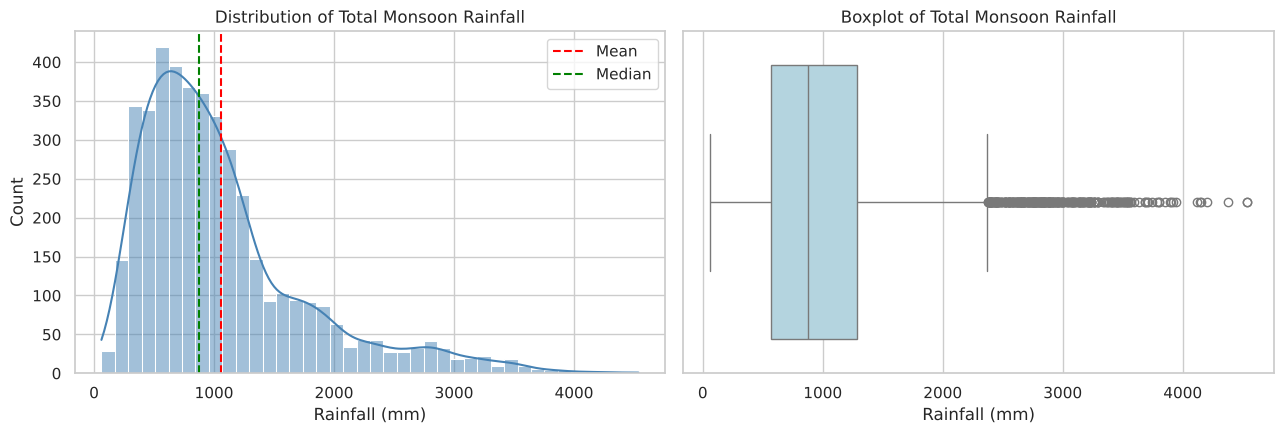

In [10]:
# Distribution of total monsoon rainfall (JUN-SEP)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_clean['TOTAL'], bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].axvline(df_clean['TOTAL'].mean(), color='red', linestyle='--', label='Mean')
axes[0].axvline(df_clean['TOTAL'].median(), color='green', linestyle='--', label='Median')
axes[0].set_title('Distribution of Total Monsoon Rainfall')
axes[0].set_xlabel('Rainfall (mm)')
axes[0].legend()

sns.boxplot(x=df_clean['TOTAL'], color='lightblue', ax=axes[1])
axes[1].set_title('Boxplot of Total Monsoon Rainfall')
axes[1].set_xlabel('Rainfall (mm)')

plt.tight_layout()
plt.savefig('images/01_total_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('Mean   :', round(df_clean['TOTAL'].mean(), 1), 'mm')
print('Median :', round(df_clean['TOTAL'].median(), 1), 'mm')
print('Skewness:', round(df_clean['TOTAL'].skew(), 2))

**Observations**

- The distribution is **skewed to the right** (skewness = 1.53). The mean (1059.8 mm) is higher than the median (878.8 mm).
- Half of the records lie between about 567 mm and 1289 mm, but a long tail reaches up to 4,537 mm.
- The histogram mixes very dry and very wet regions, which is why it is so spread out.

### 5.2 Distribution of monthly rainfall

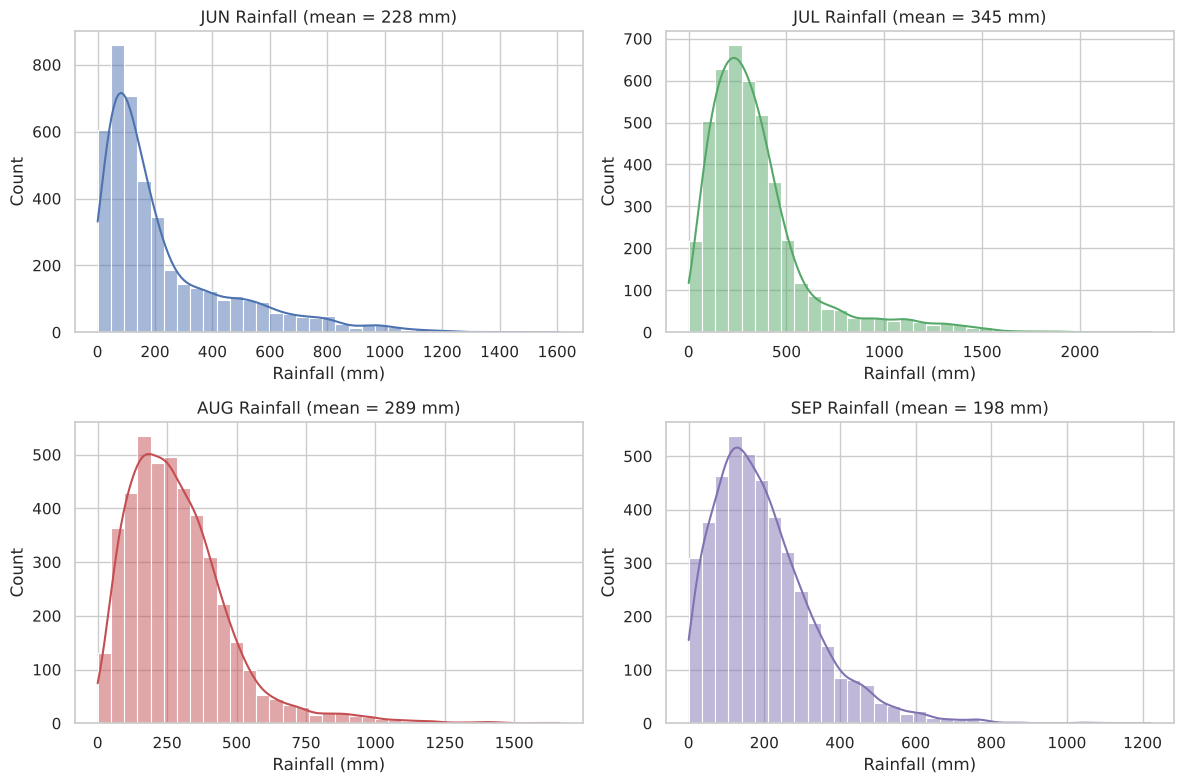

In [11]:
# Histograms of monthly rainfall
months = ['JUN', 'JUL', 'AUG', 'SEP']
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, month, color in zip(axes.flatten(), months, colors):
    sns.histplot(df_clean[month], bins=35, kde=True, color=color, ax=ax)
    ax.set_title(f'{month} Rainfall (mean = {df_clean[month].mean():.0f} mm)')
    ax.set_xlabel('Rainfall (mm)')

plt.tight_layout()
plt.savefig('images/02_monthly_histograms.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations**

- All four months are right-skewed: many records with low or moderate rainfall and a few with very heavy rainfall.
- **July** has the highest average (344 mm) and the widest spread.
- **June** has a large gap between mean (228 mm) and median (138 mm). A late or early start of the monsoon makes June rainfall very different from year to year.

### 5.3 Year-wise trend

Linear trend: -1.7 mm per decade
Wettest year : 1961 (1252 mm)
Driest year  : 1972 (817 mm)


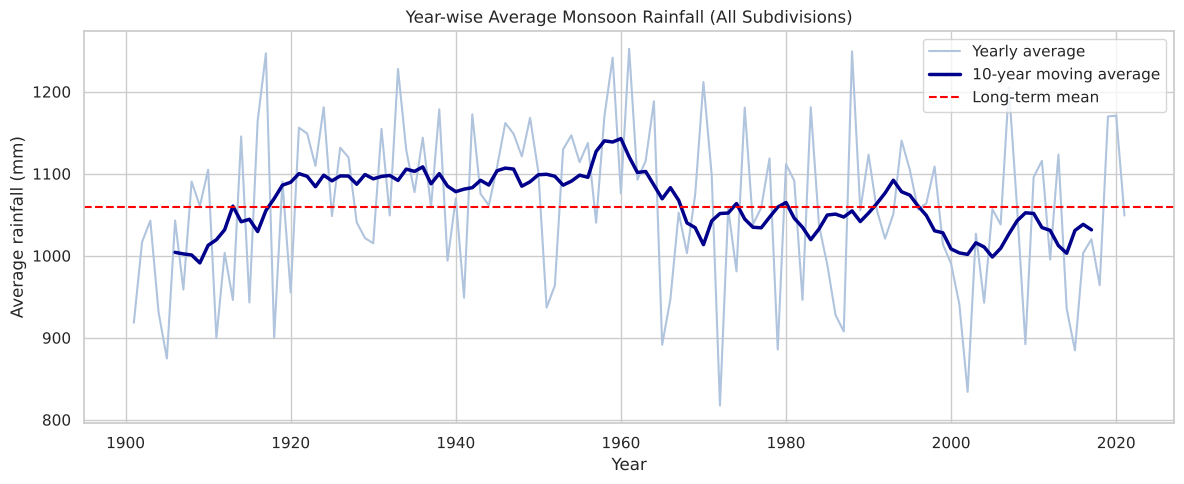

In [12]:
# Year-wise trend: average rainfall across all subdivisions for each year
yearly = df_clean.groupby('YEAR')['TOTAL'].mean()
rolling = yearly.rolling(window=10, center=True).mean()

plt.figure(figsize=(12, 5))
plt.plot(yearly.index, yearly.values, color='lightsteelblue', label='Yearly average')
plt.plot(rolling.index, rolling.values, color='darkblue', linewidth=2.5, label='10-year moving average')
plt.axhline(yearly.mean(), color='red', linestyle='--', label='Long-term mean')
plt.title('Year-wise Average Monsoon Rainfall (All Subdivisions)')
plt.xlabel('Year')
plt.ylabel('Average rainfall (mm)')
plt.legend()
plt.tight_layout()
plt.savefig('images/03_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()

# Simple straight-line trend
slope, intercept = np.polyfit(yearly.index, yearly.values, 1)
print(f'Linear trend: {slope * 10:.1f} mm per decade')
print('Wettest year :', yearly.idxmax(), f'({yearly.max():.0f} mm)')
print('Driest year  :', yearly.idxmin(), f'({yearly.min():.0f} mm)')

**Observations**

- There is **no clear long-term trend**. The straight-line trend is only about -1.7 mm per decade, which is tiny compared with the average of about 1,060 mm.
- The 30-year averages are similar: 1044 mm (1901-1930), 1103 mm (1931-1960), 1056 mm (1961-1990) and 1037 mm (1991-2021). The period 1931-1960 was a little wetter.
- The yearly average moves up and down a lot. The wettest year was 1961 (1252 mm) and the driest was 1972 (817 mm). This means the year alone is not a useful predictor.

### 5.4 Monthly trends

JUN    21.5 % of the season total
JUL    32.6 % of the season total
AUG    27.3 % of the season total
SEP    18.7 % of the season total
dtype: str

             JUN    JUL    AUG    SEP
PERIOD                               
1901-1930  230.0  340.0  282.0  193.0
1931-1960  235.0  368.0  294.0  207.0
1961-1990  223.0  342.0  298.0  193.0
1991-2021  223.0  332.0  284.0  198.0


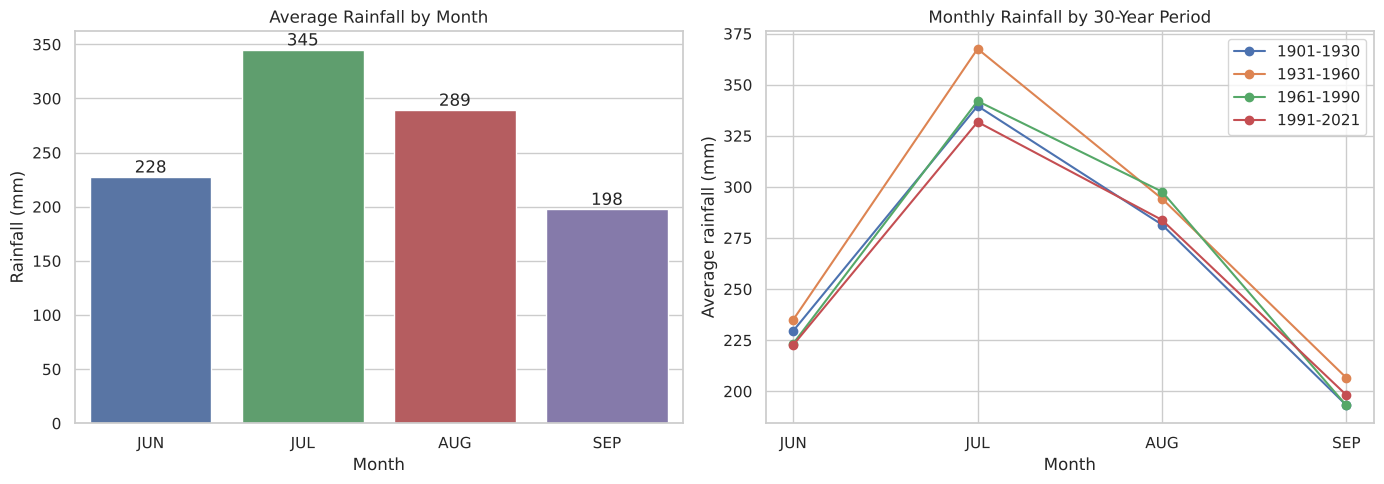

In [13]:
# Monthly trends
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Average rainfall of each month
monthly_mean = df_clean[months].mean()
sns.barplot(x=monthly_mean.index, y=monthly_mean.values, palette=colors, ax=axes[0])
for i, v in enumerate(monthly_mean.values):
    axes[0].text(i, v + 4, f'{v:.0f}', ha='center')
axes[0].set_title('Average Rainfall by Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Rainfall (mm)')

# (b) How the monthly pattern changed across 30-year periods
period_mean = df_clean.groupby('PERIOD')[months].mean()
for period, row in period_mean.iterrows():
    axes[1].plot(months, row.values, marker='o', label=period)
axes[1].set_title('Monthly Rainfall by 30-Year Period')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average rainfall (mm)')
axes[1].legend()

plt.tight_layout()
plt.savefig('images/04_monthly_trends.png', dpi=150, bbox_inches='tight')
plt.show()

print((monthly_mean / monthly_mean.sum() * 100).round(1).astype(str) + ' % of the season total')
print()
print(period_mean.round(0))

**Observations**

- **July** is the wettest month and gives 32.6% of the seasonal rainfall, followed by August (27.3%), June (21.5%) and September (18.7%).
- The monthly pattern is almost the same in all four 30-year periods. The only visible difference is a higher July in 1931-1960 (368 mm compared with 332-342 mm in the other periods).
- So the shape of the monsoon season has stayed stable over the last century.

### 5.5 Subdivision-wise rainfall

Top 3 wettest : Coastal Karnataka (2977), Konkan & Goa (2825), Arunachal Pradesh (2233)
Top 3 driest  : West Rajasthan (264), Tamil Nadu, Puducherry & Karaikal (329), Rayalseema (385)


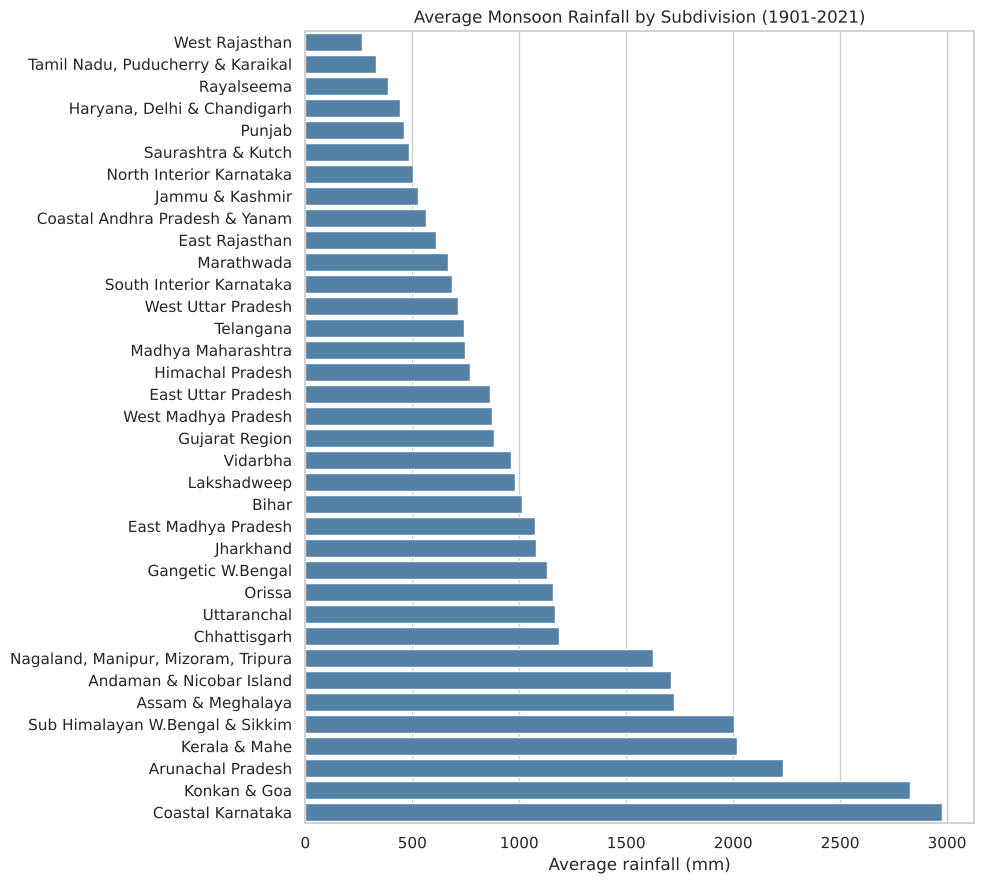

In [14]:
# Average monsoon rainfall of every subdivision
sub_mean = df_clean.groupby('subdivision')['TOTAL'].mean().sort_values()

plt.figure(figsize=(10, 9))
sns.barplot(x=sub_mean.values, y=sub_mean.index, color='steelblue')
plt.title('Average Monsoon Rainfall by Subdivision (1901-2021)')
plt.xlabel('Average rainfall (mm)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('images/05_subdivision_average.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 3 wettest :', ', '.join(f'{n} ({v:.0f})' for n, v in sub_mean.tail(3)[::-1].items()))
print('Top 3 driest  :', ', '.join(f'{n} ({v:.0f})' for n, v in sub_mean.head(3).items()))

**Observations**

- Rainfall differs a lot between regions. The wettest are **Coastal Karnataka (2977 mm)**, **Konkan & Goa (2825 mm)** and **Arunachal Pradesh (2233 mm)**.
- The driest are **West Rajasthan (264 mm)**, **Tamil Nadu, Puducherry & Karaikal (329 mm)** and **Rayalseema (385 mm)**. Tamil Nadu receives most of its rain from the north-east monsoon in October-December, which is outside this dataset.
- The wettest region receives more than 11 times the rainfall of the driest one. The **subdivision is clearly an important feature**.

### 5.6 Boxplots

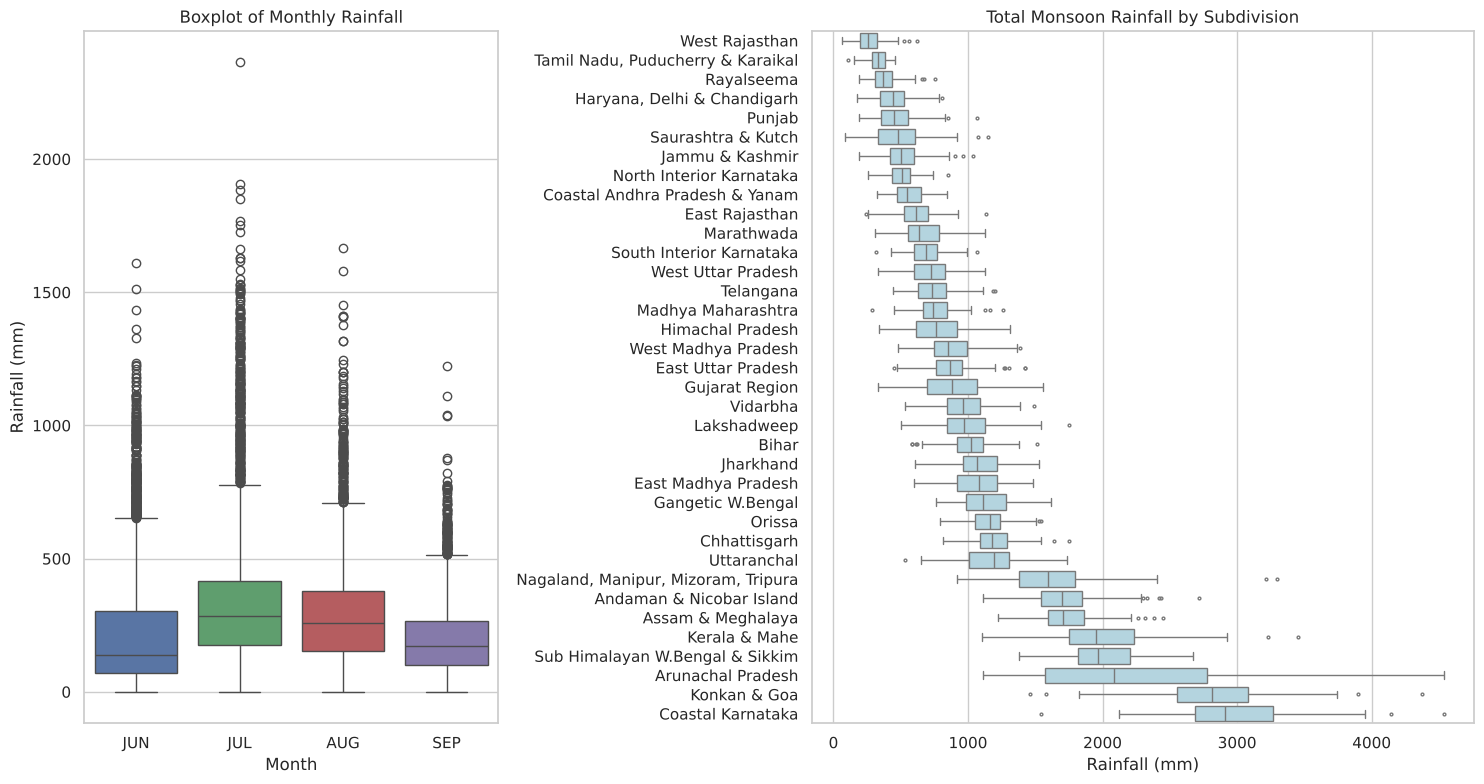

In [15]:
# Boxplots: monthly rainfall and subdivision-wise rainfall
fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={'width_ratios': [1, 1.6]})

sns.boxplot(data=df_clean[months], palette=colors, ax=axes[0])
axes[0].set_title('Boxplot of Monthly Rainfall')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Rainfall (mm)')

order = df_clean.groupby('subdivision')['TOTAL'].median().sort_values().index
sns.boxplot(data=df_clean, x='TOTAL', y='subdivision', order=order, color='lightblue',
            fliersize=2, ax=axes[1])
axes[1].set_title('Total Monsoon Rainfall by Subdivision')
axes[1].set_xlabel('Rainfall (mm)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('images/06_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations**

- All four months have many points above the upper whisker, which confirms the heavy right tail seen in the histograms.
- Wet regions have wide boxes, which means large changes from year to year (standard deviation: Arunachal Pradesh 812 mm, Konkan & Goa 484 mm, Coastal Karnataka 460 mm).
- Dry regions have narrow boxes in mm, but they are the most unpredictable in relative terms. The variation compared with the average is highest for Saurashtra & Kutch (43%) and West Rajasthan (38%), and lowest for Orissa (13%) and Assam & Meghalaya (14%).

### 5.7 Correlation heatmap

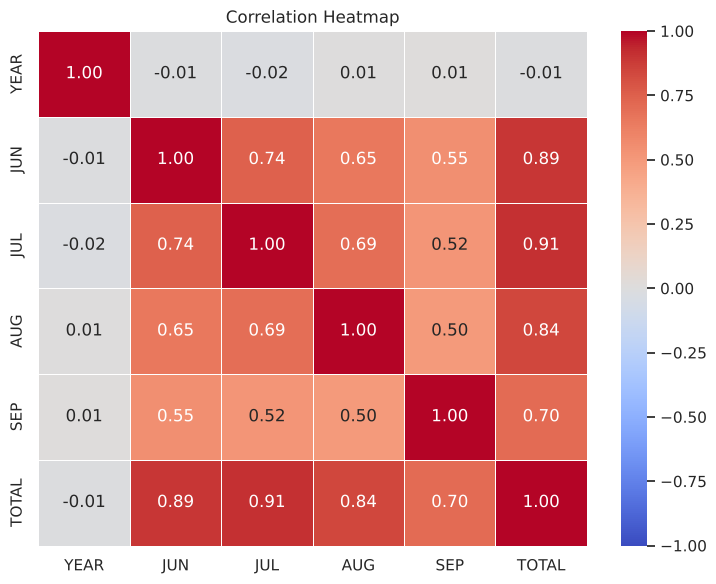

In [16]:
# Correlation heatmap
corr = df_clean[['YEAR', 'JUN', 'JUL', 'AUG', 'SEP', 'TOTAL']].corr()

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('images/07_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations**

- All four months are positively correlated with the seasonal total. **July (0.91)** and **June (0.89)** have the strongest link and September (0.70) the weakest.
- The months are also correlated with each other (0.50 to 0.74). A wet June often goes with a wet July.
- `YEAR` has a correlation of almost zero (-0.01) with every column, which supports the finding that there is no time trend.
- August and September are *parts of* the total, so their high correlation is partly automatic. We will not use them as model inputs (explained in the next section).

### 5.8 Class balance

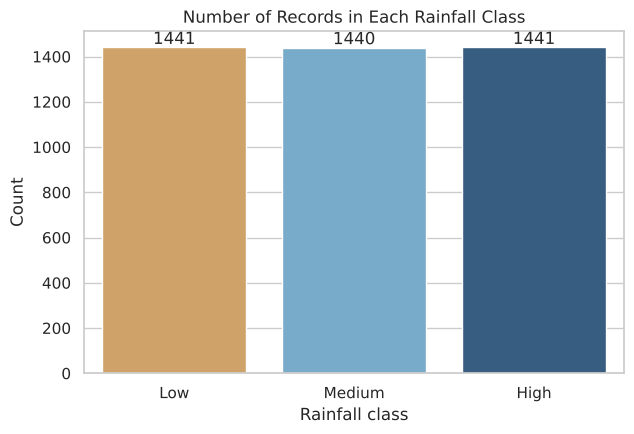

In [17]:
# Class balance of the rainfall categories
order = ['Low', 'Medium', 'High']
plt.figure(figsize=(6.5, 4.5))
ax = sns.countplot(data=df_clean, x='CLASS', order=order, palette=['#E0A458', '#6BAED6', '#2B5D8C'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height() + 15), ha='center')
plt.title('Number of Records in Each Rainfall Class')
plt.xlabel('Rainfall class')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('images/08_class_balance.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:** The three classes are balanced (about 1,440 rows each), so **accuracy is a fair metric** and no resampling is needed.

---
## 6. Problem Setup and Train-Test Split

**What are we predicting?** We predict the seasonal rainfall of a subdivision using what is known *after July*: the subdivision, the year, and the June and July rainfall. This works like a **mid-season estimate** for the remaining monsoon.

**Why not use August and September?** Together with June and July they add up exactly to the target. Using them would be *data leakage*: the model would just add four numbers and look perfect without learning anything useful.

**Preprocessing**
- `subdivision` is text, so it is **one-hot encoded**.
- `YEAR`, `JUN`, `JUL` and `JUN_JUL` are **scaled** with `StandardScaler` (needed for Logistic Regression and Linear Regression).
- Encoding and scaling are placed inside a `Pipeline`, so they are learned from the training data only. This prevents information from the test set leaking into the training step.

In [18]:
# Features (inputs) and targets (outputs)
features = ['subdivision', 'YEAR', 'JUN', 'JUL', 'JUN_JUL']
cat_cols = ['subdivision']
num_cols = ['YEAR', 'JUN', 'JUL', 'JUN_JUL']

X = df_clean[features]
y_class = df_clean['CLASS']      # target for classification
y_reg = df_clean['TOTAL']        # target for regression

# One common 80/20 split is used for both tasks so results are comparable.
# stratify keeps the Low / Medium / High ratio the same in both sets.
X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_class, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=y_class)

print('Training rows:', X_train.shape[0])
print('Testing rows :', X_test.shape[0])

# Preprocessing: one-hot encode the subdivision and scale the numeric columns.
def make_preprocessor():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', StandardScaler(), num_cols)
    ])

Training rows: 3457
Testing rows : 865


---
## 7. Classification Models

We train three models and also a **baseline** that always predicts the most common class. A good model must clearly beat this baseline. Precision, recall and F1 are **macro-averaged**, which means the three classes get equal weight.

In [19]:
# Classification models
class_labels = ['Low', 'Medium', 'High']

clf_models = {
    'Baseline (Most Frequent)': Pipeline([('prep', make_preprocessor()),
        ('model', DummyClassifier(strategy='most_frequent'))]),

    'Logistic Regression': Pipeline([('prep', make_preprocessor()),
        ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),

    # Decision Tree and Random Forest use a small grid search to choose settings
    'Decision Tree': GridSearchCV(
        Pipeline([('prep', make_preprocessor()),
                  ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        param_grid={'model__max_depth': [3, 4, 5, 6, 8, 12, None],
                    'model__min_samples_leaf': [1, 5, 10]},
        cv=5, scoring='f1_macro'),

    'Random Forest': GridSearchCV(
        Pipeline([('prep', make_preprocessor()),
                  ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        param_grid={'model__n_estimators': [100, 200],
                    'model__max_depth': [10, 20, None],
                    'model__min_samples_leaf': [1, 3]},
        cv=3, scoring='f1_macro'),
}

def cv_score(model, X, y, scoring):
    """5-fold CV score on training data (grid-search models already have one)."""
    if hasattr(model, 'best_score_'):
        return model.best_score_
    return cross_val_score(model, X, y, cv=5, scoring=scoring).mean()

clf_rows, clf_preds = [], {}
for name, model in clf_models.items():
    model.fit(X_train, yc_train)
    pred = model.predict(X_test)
    clf_preds[name] = pred
    clf_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(yc_test, pred),
        'Precision': precision_score(yc_test, pred, average='macro'),
        'Recall': recall_score(yc_test, pred, average='macro'),
        'F1 Score': f1_score(yc_test, pred, average='macro'),
        'CV F1 (train)': cv_score(model, X_train, yc_train, 'f1_macro'),
    })

clf_results = pd.DataFrame(clf_rows).set_index('Model').round(4)
print('Best settings found:')
print('  Decision Tree :', clf_models['Decision Tree'].best_params_)
print('  Random Forest :', clf_models['Random Forest'].best_params_)
print('\nClassification results on the test set (macro-averaged):')
clf_results

Best settings found:
  Decision Tree : {'model__max_depth': 3, 'model__min_samples_leaf': 1}
  Random Forest : {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}

Classification results on the test set (macro-averaged):


,Accuracy,Precision,Recall,F1 Score,CV F1 (train)
Model,,,,,
Baseline (Most Frequent),0.3329,0.1110,0.3333,0.1665,0.1666
Logistic Regression,0.8486,0.8501,0.8485,0.8491,0.8438
Decision Tree,0.8116,0.8237,0.8115,0.8148,0.8282
Random Forest,0.8220,0.8309,0.8219,0.8246,0.8393


Best classifier: Logistic Regression
              precision    recall  f1-score   support

         Low      0.872     0.875     0.873       288
      Medium      0.764     0.788     0.776       288
        High      0.914     0.882     0.898       289

    accuracy                          0.849       865
   macro avg      0.850     0.849     0.849       865
weighted avg      0.850     0.849     0.849       865



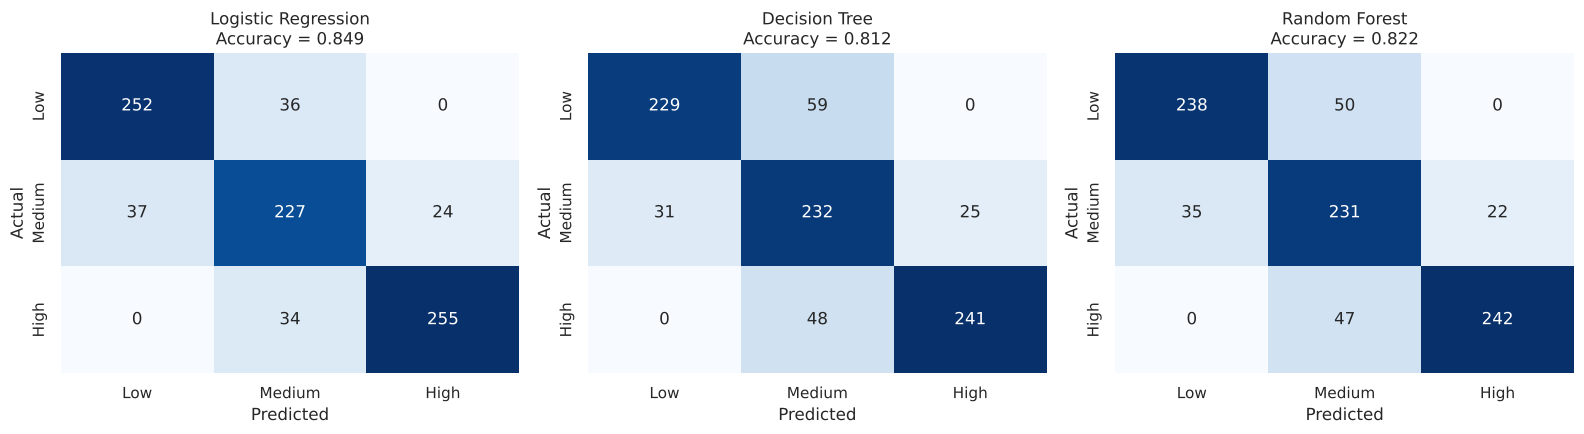

In [20]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, ['Logistic Regression', 'Decision Tree', 'Random Forest']):
    cm = confusion_matrix(yc_test, clf_preds[name], labels=class_labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=class_labels, yticklabels=class_labels)
    ax.set_title(f'{name}\nAccuracy = {accuracy_score(yc_test, clf_preds[name]):.3f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('images/09_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

# Detailed report for the best classifier
best_clf_name = clf_results.drop('Baseline (Most Frequent)')['F1 Score'].idxmax()
print('Best classifier:', best_clf_name)
print(classification_report(yc_test, clf_preds[best_clf_name], labels=class_labels, digits=3))

**Observations**

- All three models are far better than the baseline (accuracy 0.333, which is the same as random guessing for three equal classes).
- **Logistic Regression** is the best: accuracy **0.849**, F1 **0.849**. Random Forest follows (0.822) and then Decision Tree (0.812, with a depth of only 3 chosen by grid search).
- The **Medium** class is the hardest (F1 about 0.78) because it lies between the other two. In the confusion matrix, almost every mistake is a **neighbouring class**. For Logistic Regression, no Low record was predicted as High and no High record as Low.
- The class depends a lot on the region. For example, West Rajasthan and Tamil Nadu are always Low and Coastal Karnataka, Konkan & Goa and Assam & Meghalaya are always High. So part of the accuracy comes from knowing the region.

---
## 8. Regression Models

Here the target is the actual total rainfall in mm. A baseline that always predicts the average is included for reference.

In [21]:
# Regression models
reg_models = {
    'Baseline (Mean)': Pipeline([('prep', make_preprocessor()),
        ('model', DummyRegressor(strategy='mean'))]),

    'Linear Regression': Pipeline([('prep', make_preprocessor()),
        ('model', LinearRegression())]),

    'Decision Tree': GridSearchCV(
        Pipeline([('prep', make_preprocessor()),
                  ('model', DecisionTreeRegressor(random_state=RANDOM_STATE))]),
        param_grid={'model__max_depth': [3, 4, 5, 6, 8, 12, None],
                    'model__min_samples_leaf': [1, 5, 10]},
        cv=5, scoring='neg_root_mean_squared_error'),

    'Random Forest': GridSearchCV(
        Pipeline([('prep', make_preprocessor()),
                  ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
        param_grid={'model__n_estimators': [100, 200],
                    'model__max_depth': [10, 20, None],
                    'model__min_samples_leaf': [1, 3]},
        cv=3, scoring='neg_root_mean_squared_error'),
}

reg_rows, reg_preds = [], {}
for name, model in reg_models.items():
    model.fit(X_train, yr_train)
    pred = model.predict(X_test)
    reg_preds[name] = pred
    reg_rows.append({
        'Model': name,
        'MAE': mean_absolute_error(yr_test, pred),
        'RMSE': np.sqrt(mean_squared_error(yr_test, pred)),
        'R2 Score': r2_score(yr_test, pred),
        'CV RMSE (train)': -cv_score(reg_models[name], X_train, yr_train, 'neg_root_mean_squared_error'),
    })

reg_results = pd.DataFrame(reg_rows).set_index('Model').round(4)
print('Best settings found:')
print('  Decision Tree :', reg_models['Decision Tree'].best_params_)
print('  Random Forest :', reg_models['Random Forest'].best_params_)
print('\nRegression results on the test set:')
reg_results

Best settings found:
  Decision Tree : {'model__max_depth': 6, 'model__min_samples_leaf': 5}
  Random Forest : {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}

Regression results on the test set:


,MAE,RMSE,R2 Score,CV RMSE (train)
Model,,,,
Baseline (Mean),538.4557,739.6783,-0.0011,695.8529
Linear Regression,111.8182,156.7825,0.9550,155.8569
Decision Tree,129.9071,174.7735,0.9441,178.3539
Random Forest,115.6308,162.3785,0.9518,167.7065


Best regressor: Linear Regression
Mean error (bias): 0.2 mm


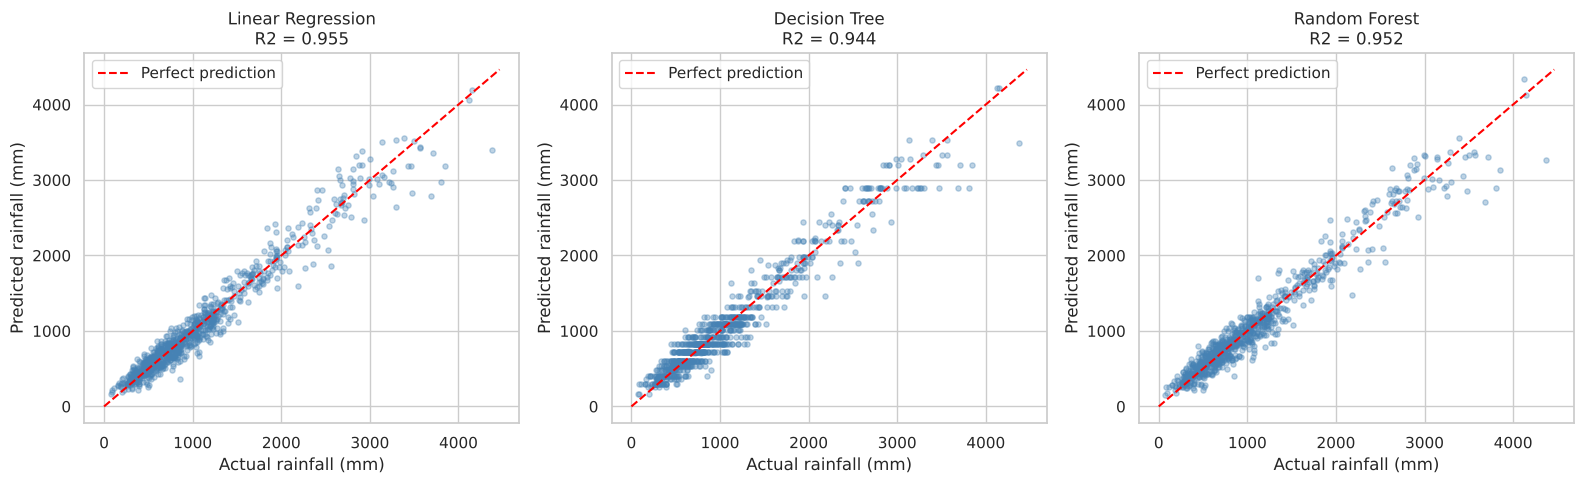

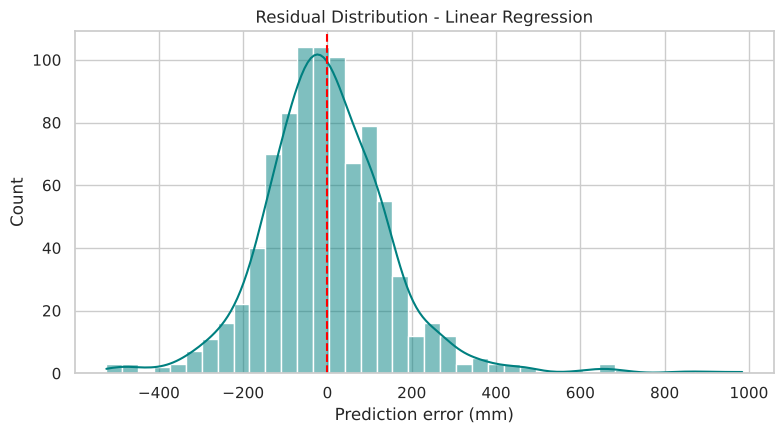

In [22]:
# Actual vs predicted rainfall
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
lims = [0, yr_test.max() * 1.02]
for ax, name in zip(axes, ['Linear Regression', 'Decision Tree', 'Random Forest']):
    ax.scatter(yr_test, reg_preds[name], alpha=0.35, s=14, color='steelblue')
    ax.plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
    ax.set_title(f'{name}\nR2 = {r2_score(yr_test, reg_preds[name]):.3f}')
    ax.set_xlabel('Actual rainfall (mm)')
    ax.set_ylabel('Predicted rainfall (mm)')
    ax.legend()
plt.tight_layout()
plt.savefig('images/10_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

# Residuals (error = actual - predicted) of the best regressor
best_reg_name = reg_results.drop('Baseline (Mean)')['RMSE'].idxmin()
residuals = yr_test - reg_preds[best_reg_name]
plt.figure(figsize=(8, 4.5))
sns.histplot(residuals, bins=40, kde=True, color='teal')
plt.axvline(0, color='red', linestyle='--')
plt.title(f'Residual Distribution - {best_reg_name}')
plt.xlabel('Prediction error (mm)')
plt.tight_layout()
plt.savefig('images/11_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print('Best regressor:', best_reg_name)
print('Mean error (bias):', round(residuals.mean(), 1), 'mm')

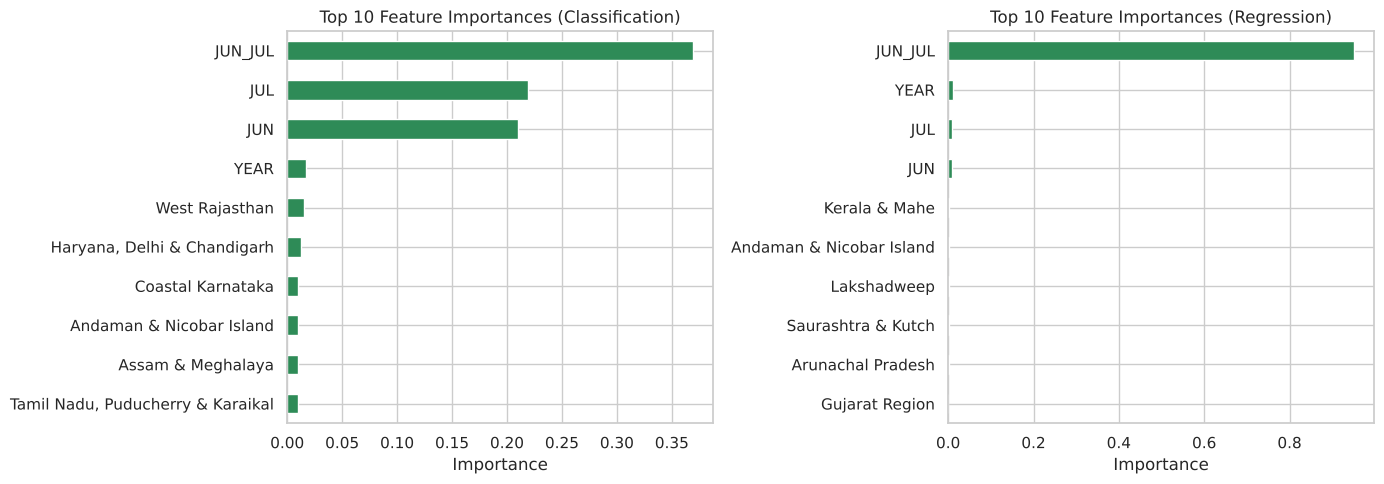

In [23]:
# Which features matter most? (Random Forest)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (title, grid) in zip(axes, [('Classification', clf_models['Random Forest']),
                                    ('Regression', reg_models['Random Forest'])]):
    pipe = grid.best_estimator_
    names = pipe.named_steps['prep'].get_feature_names_out()
    names = [n.replace('cat__subdivision_', '').replace('num__', '') for n in names]
    imp = pd.Series(pipe.named_steps['model'].feature_importances_, index=names)
    imp.sort_values().tail(10).plot(kind='barh', color='seagreen', ax=ax)
    ax.set_title(f'Top 10 Feature Importances ({title})')
    ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('images/12_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

**Observations**

- **Linear Regression** is the best model: **MAE 111.8 mm, RMSE 156.8 mm, R² 0.955**. Random Forest is very close (R² 0.952) and Decision Tree is a little behind (R² 0.944). The baseline has R² of about 0, as expected.
- The average error of 112 mm is about **10.6%** of the mean seasonal rainfall (1060 mm).
- The residuals are centred near zero (average error 0.2 mm), so the model does not over-predict or under-predict on average.
- In the actual-vs-predicted plots the points follow the red line closely. The scatter is larger for heavy rainfall. By region, the Linear Regression error is largest for Konkan & Goa (266 mm), Arunachal Pradesh (247 mm) and Coastal Karnataka (203 mm), and smallest for Tamil Nadu (49 mm).
- The feature importance chart shows that **June + July rainfall is by far the most important input**, and the year has almost no effect. This matches the EDA.

---
## 9. Model Comparison

Best classification model: Logistic Regression (F1 = 0.8491 )
Best regression model    : Linear Regression (RMSE = 156.7825 mm, R2 = 0.955 )
Average total rainfall   : 1059.8 mm  -> MAE is 10.6 % of this


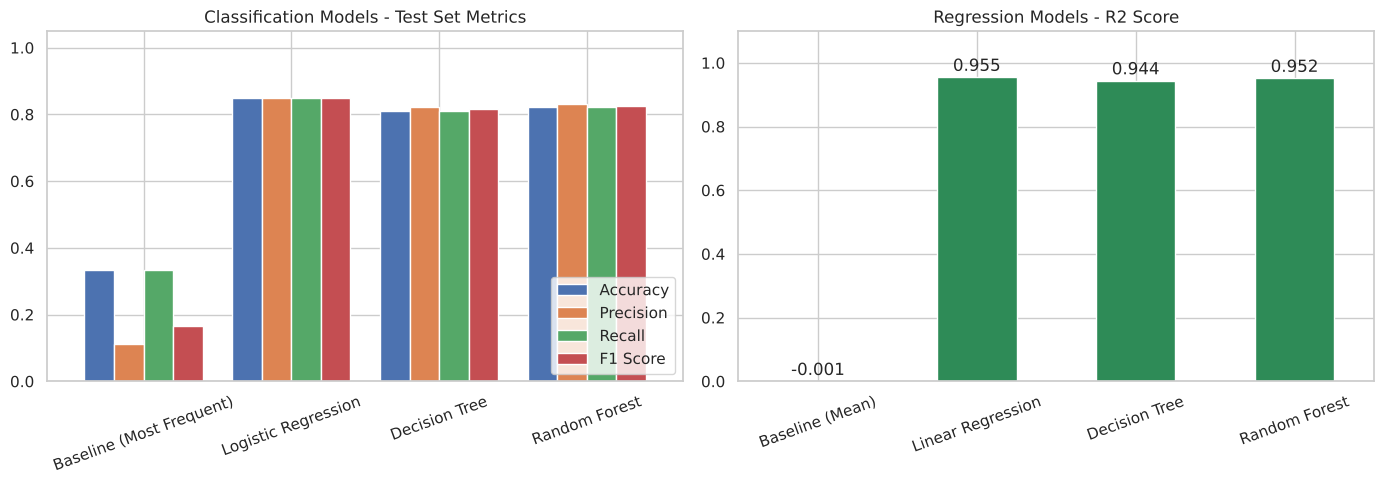

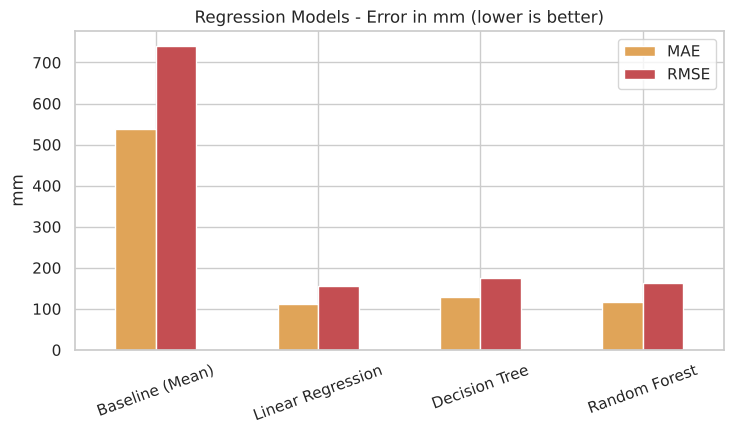

In [24]:
# Side-by-side comparison charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

clf_plot = clf_results[['Accuracy', 'Precision', 'Recall', 'F1 Score']]
clf_plot.plot(kind='bar', ax=axes[0], rot=20, width=0.8)
axes[0].set_title('Classification Models - Test Set Metrics')
axes[0].set_ylim(0, 1.05)
axes[0].set_xlabel('')
axes[0].legend(loc='lower right')

reg_results[['R2 Score']].plot(kind='bar', ax=axes[1], rot=20, color='seagreen', legend=False)
for i, v in enumerate(reg_results['R2 Score']):
    axes[1].text(i, max(v, 0) + 0.02, f'{v:.3f}', ha='center')
axes[1].set_title('Regression Models - R2 Score')
axes[1].set_ylim(0, 1.1)
axes[1].set_xlabel('')

plt.tight_layout()
plt.savefig('images/13_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.5))
reg_results[['MAE', 'RMSE']].plot(kind='bar', ax=ax, rot=20, color=['#E0A458', '#C44E52'])
ax.set_title('Regression Models - Error in mm (lower is better)')
ax.set_xlabel('')
ax.set_ylabel('mm')
plt.tight_layout()
plt.savefig('images/14_regression_errors.png', dpi=150, bbox_inches='tight')
plt.show()

best_clf = clf_results.drop('Baseline (Most Frequent)')['F1 Score'].idxmax()
best_reg = reg_results.drop('Baseline (Mean)')['RMSE'].idxmin()
print('Best classification model:', best_clf, '(F1 =', clf_results.loc[best_clf, 'F1 Score'], ')')
print('Best regression model    :', best_reg, '(RMSE =', reg_results.loc[best_reg, 'RMSE'], 'mm, R2 =', reg_results.loc[best_reg, 'R2 Score'], ')')
print('Average total rainfall   :', round(df_clean['TOTAL'].mean(), 1), 'mm  -> MAE is',
      round(reg_results.loc[best_reg, 'MAE'] / df_clean['TOTAL'].mean() * 100, 1), '% of this')

**Summary of results (test set, 865 records)**

| Task | Model | Main result |
|---|---|---|
| Classification | **Logistic Regression** | Accuracy 0.849, F1 0.849 |
| Classification | Random Forest | Accuracy 0.822, F1 0.825 |
| Classification | Decision Tree | Accuracy 0.812, F1 0.815 |
| Regression | **Linear Regression** | MAE 111.8, RMSE 156.8, R² 0.955 |
| Regression | Random Forest | MAE 115.6, RMSE 162.4, R² 0.952 |
| Regression | Decision Tree | MAE 129.9, RMSE 174.8, R² 0.944 |

**Observations**

- **Best classifier: Logistic Regression. Best regressor: Linear Regression.**
- The simple linear models won in both tasks. The reason is that the main relationship is almost a straight line: the seasonal total grows steadily with June + July rainfall. Linear models describe this directly, while trees have to approximate a line with steps.
- Random Forest is a close second and is always better than a single Decision Tree, which is the usual behaviour because averaging many trees reduces overfitting.
- The cross-validation scores on the training data are close to the test scores, so the models are not badly overfitted.

---
## 10. Saving the Best Models

The best classifier and regressor (complete pipelines, including encoding and scaling) are saved with Pickle so that they can be used again without retraining.

In [25]:
# Save the best models with Pickle
def get_fitted(model):
    """Return the fitted pipeline (the best one if a grid search was used)."""
    return model.best_estimator_ if hasattr(model, 'best_estimator_') else model

best_classifier = get_fitted(clf_models[best_clf])
best_regressor = get_fitted(reg_models[best_reg])

with open('models/best_classifier.pkl', 'wb') as f:
    pickle.dump(best_classifier, f)
with open('models/best_regressor.pkl', 'wb') as f:
    pickle.dump(best_regressor, f)

# Save the class boundaries so predictions can be explained later
with open('models/class_thresholds.json', 'w') as f:
    json.dump(class_thresholds, f)

# Save all results (used while writing the report)
def best_params(model):
    return {k: str(v) for k, v in model.best_params_.items()} if hasattr(model, 'best_params_') else {}

with open('models/results.json', 'w') as f:
    json.dump({'classification': clf_results.reset_index().to_dict('records'),
               'regression': reg_results.reset_index().to_dict('records'),
               'best_classifier': best_clf, 'best_regressor': best_reg,
               'thresholds': class_thresholds,
               'train_rows': int(X_train.shape[0]), 'test_rows': int(X_test.shape[0]),
               'clf_params': best_params(clf_models[best_clf]),
               'reg_params': best_params(reg_models[best_reg])}, f, indent=2)
print('Saved: models/best_classifier.pkl, models/best_regressor.pkl')

Saved: models/best_classifier.pkl, models/best_regressor.pkl


In [26]:
# Load the saved models and make a sample prediction
with open('models/best_classifier.pkl', 'rb') as f:
    loaded_clf = pickle.load(f)
with open('models/best_regressor.pkl', 'rb') as f:
    loaded_reg = pickle.load(f)

# One example record from the test set
sample = X_test.iloc[[0]]
print('Input record:')
print(sample.to_string(index=False))
print('\nPredicted rainfall class :', loaded_clf.predict(sample)[0], '  (actual:', yc_test.iloc[0] + ')')
print('Predicted total rainfall :', round(loaded_reg.predict(sample)[0], 1), 'mm  (actual:', round(yr_test.iloc[0], 1), 'mm)')

Input record:
       subdivision  YEAR   JUN   JUL  JUN_JUL
Madhya Maharashtra  1959 174.7 344.3    519.0

Predicted rainfall class : Medium   (actual: Medium)
Predicted total rainfall : 890.8 mm  (actual: 920.7 mm)


---
## 11. Conclusion and Future Scope

### Conclusion

- The dataset looked clean at first, but the value **-99.9** was hiding 10 missing records. These were found and removed during cleaning.
- EDA showed that rainfall depends mainly on the **region**, that **July** is the wettest month, and that there is **no strong trend over the years**.
- For classification into Low / Medium / High, **Logistic Regression** gave the best result with **84.9% accuracy**.
- For predicting the seasonal rainfall, **Linear Regression** gave the best result with **R² = 0.955** and an average error of about **112 mm**.
- Simple models can perform better than complex ones when the relationship in the data is mostly linear. Random Forest was a close second.

### Limitations

- The models use the **actual June and July rainfall of the same year**. They give a mid-season estimate, not a forecast made before the monsoon begins.
- Only rainfall data is used. Temperature, humidity, sea-surface temperature and El Nino are not included.
- The data is split randomly, so the same subdivision appears in both training and test sets. A split by year would be a stricter test.
- The class boundaries were calculated from the whole dataset.
- The data is at subdivision level, not for individual cities or districts.

### Future Scope

1. Add climate variables such as El Nino / La Nina, Indian Ocean Dipole, temperature and humidity.
2. Test the models with a **time-based split** (train on older years, test on recent years).
3. Build a separate model for each region or climate zone.
4. Try other scikit-learn models such as Gradient Boosting and K-Nearest Neighbours, and tune them more.
5. Build a small web app (for example with Streamlit) where a user selects a subdivision and enters June and July rainfall to get a prediction.
6. Extend the data with October-December and January-May rainfall for a full-year study.